# After the prospective test: two more predictions, a repaired fit, and a ceiling

`KAN_Prospective_Test` scored nine predictions on outside tables. This notebook does three
things that followed from it.

1. **Two more predictions, written first** (`PROSPECTIVE_TEST.md`, commits d990d5ee and
   a14a94bd, each before its table was opened). *H10*: the buried-volume window marks the active
   ligands among 28 further phosphines screened in the reactions the window came from
   (LeSueur, Tao, Doyle, Sigman, *Eur. J. Org. Chem.* 2024). *H11*: for Pd the active side is
   above the cut, in eight Pd-catalysed reactions reprinted in the same supporting information.
2. **A repaired fit.** The outside test exposed a defect in the yes/no fit of `transferledger`
   0.1: on a nearly separated outcome the iteration overshot and alternated between two bad
   fits. On the Ni table the curves rung scored -2.8 on random folds. Version 0.2 shortens a
   step that would raise the penalized deviance. H3 to H6, the predictions scored with that
   fit, are run again here exactly as registered. The registered verdicts stand as the record;
   the repeated ones are shown next to them.
3. **A ceiling.** The Ni reactions of the outside table turned out to owe their activity to a
   metal-free background, so a ligand property had nothing to mark. `unit_ceiling` (new in 0.2)
   measures that directly: what knowing the ligand adds, once the conditions are known.
   A last section, post hoc, asks the same of Pd, runs the ledger there, and asks what its 53
   ligands could have shown.

Data are downloaded at run time (Zenodo record 15652094 for the supporting information, which
needs `pypdf`; the Open Reaction Database for the Cernak table, which needs `ord-schema`). A
full run takes about three and a quarter hours on four cores with `transferledger` 0.2.1; with
`PROSP_RESUME` set to a folder, each long step is kept there and an interrupted run continues.

In [1]:
import gzip
import io
import json
import os
import re
import time
import urllib.request
import warnings
import zipfile

warnings.filterwarnings("ignore")

import importlib.metadata as imd

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypdf
from IPython.display import display
from joblib import Parallel, delayed
from rdkit import Chem, RDLogger
from scipy.stats import mannwhitneyu

from pycse.sklearn._plotstyle import BASELINE, MUTED, PX, SERIES, finish_axes, style_axes
from pycse.sklearn.kan_interpret import prune_collinear
from transferledger import (
    NewGroups,
    PieceModel,
    backtest,
    detectable,
    transfer_ledger,
    unit_ceiling,
)

RDLogger.DisableLog("rdApp.*")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
N_JOBS = int(os.environ.get("PROSP_JOBS", 4))
CACHE = os.path.expanduser(os.environ.get("PROSP_CACHE", "~/.cache/pycse"))
os.makedirs(CACHE, exist_ok=True)
RESUME = os.environ.get("PROSP_RESUME")


def step(name, compute):
    """Run a long step and return (result, seconds). With PROSP_RESUME set to a folder the
    result is kept there, so that an interrupted run continues instead of starting over."""
    path = os.path.join(RESUME, name + ".pkl") if RESUME else None
    if path and os.path.exists(path):
        return pd.read_pickle(path)
    t0 = time.time()
    out = compute(), time.time() - t0
    if path:
        os.makedirs(RESUME, exist_ok=True)
        pd.to_pickle(out, path + ".tmp")
        os.replace(path + ".tmp", path)
    return out


for p in ("numpy", "pandas", "scikit-learn", "rdkit", "transferledger", "ord-schema", "pypdf"):
    print(p, imd.version(p))

numpy 2.5.4
pandas 3.1.0
scikit-learn 1.9.1
rdkit 2026.9.1
transferledger 0.2.1
ord-schema 0.9.6
pypdf 7.1.1


## Helpers

In [2]:
OCHEM = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/"
SPHERE = 4.0 / 3.0 * np.pi * 3.5**3  # kraken buried volumes are in cubic angstrom in a 3.5 A sphere
LO, HI = 25.1, 31.4  # the window found on 90 phosphines (KAN_Transfer_Ledger)
SCORE = {}  # hypothesis -> (verdict, one line)


def canon(s):
    # canonical SMILES of the largest fragment; a phosphonium salt (PCy3 HBF4) counts as its phosphine
    m = Chem.MolFromSmiles(str(s))
    if m is None:
        return None
    f = max(Chem.GetMolFrags(m, asMols=True), key=lambda x: x.GetNumHeavyAtoms())
    for a in f.GetAtoms():
        if a.GetSymbol() == "P" and a.GetFormalCharge() == 1 and a.GetTotalNumHs() > 0:
            a.SetFormalCharge(0)
            a.SetNumExplicitHs(0)
            a.SetNoImplicit(False)
    try:
        Chem.SanitizeMol(f)
    except Exception:
        return None
    return Chem.MolToSmiles(f)


def inchi_canon(s):
    m = Chem.MolFromInchi(str(s))
    return canon(Chem.MolToSmiles(m)) if m is not None else None


K = pd.read_csv(OCHEM + "kraken/kraken.csv")
K = K.assign(csmi=K["can_smiles"].map(canon)).dropna(subset=["csmi"]).drop_duplicates("csmi")
K["pct_Vbur_min"] = K["vbur_vbur_min"] * 100 / SPHERE
K = K.set_index("csmi")
print(len(K), "phosphines in kraken")

KRAKEN = {
    "pct_Vbur_min": ("vbur_vbur_min", 100.0 / SPHERE), "pct_Vbur_Boltz": ("vbur_vbur_boltz", 100.0 / SPHERE),
    "pct_Vbur_max": ("vbur_vbur_max", 100.0 / SPHERE), "Sterimol_B1": ("sterimol_B1_boltz", 1.0),
    "Sterimol_B5": ("sterimol_B5_boltz", 1.0), "Sterimol_L": ("sterimol_L_boltz", 1.0),
    "E_HOMO": ("fmo_e_homo_boltz", 1.0), "E_LUMO": ("fmo_e_lumo_boltz", 1.0), "V_min": ("vmin_vmin_boltz", 1.0),
    "NBO_charge_P": ("nbo_P_boltz", 1.0), "pyramidalization_P": ("pyr_P_boltz", 1.0), "dipole": ("dipolemoment_boltz", 1.0),
}  # fmt: skip


def ligand_descriptors(csmi):
    # the twelve kraken descriptors of KAN_Ligand_Reactivity_Cliff, pruned at |r| > 0.85 as there
    X = pd.DataFrame({k: K.loc[csmi, c].to_numpy(float) * s for k, (c, s) in KRAKEN.items()})
    kept, _ = prune_collinear(X.to_numpy(float), list(X.columns), 0.85, keep_first=["pct_Vbur_min"])
    return X[kept]


def onehot(series, prefix):
    return (
        pd.get_dummies(series.astype(str), prefix=prefix, prefix_sep=": ").astype(float).iloc[:, 1:]
    )


def window_test(L, label):
    # L: one row per ligand with its minimum buried volume and activity
    inside = L.vbur.between(LO, HI)
    a, b = L[inside].activity, L[~inside].activity
    p = mannwhitneyu(a, b, alternative="greater").pvalue
    print(f"{label}: {inside.sum()} ligands inside the window, mean activity {a.mean():.3f}; "
          f"{(~inside).sum()} outside, {b.mean():.3f}; one-sided Mann-Whitney p = {p:.4f}")  # fmt: skip
    return a.mean(), b.mean(), p

1229 phosphines in kraken


## 1. H10: new ligands in the reactions the window came from

LeSueur et al. screened 28 further monophosphines on the bench in two of the five Ni-catalysed
Suzuki-Miyaura couplings of the 2021 table: 4-chloroanisole with 4-(trifluoromethyl)phenyl- and
4-(ethoxycarbonyl)phenylboronic acid (their reactions II and IV; supporting information, Tables
S8 and S9). The tables give kraken identifiers, so the minimum buried volume is read from the
kraken library by identifier.

*H10*: over the ligands that are not among the 90 phosphines of `KAN_Ligand_Reactivity_Cliff`,
those inside the window (25.1 to 31.4 %) have a higher activity than those outside (one-sided
Mann-Whitney over ligands, p < 0.05), and "inside the window is active" has a balanced accuracy
of at least 0.65 over the ligand-reaction pairs. Active is a yield of at least 10 %.

28 ligands in each of 2 reactions; 23 are not among the 90 phosphines of the cliff table
new ligands: 17 ligands inside the window, mean activity 0.735; 6 outside, 0.167; one-sided Mann-Whitney p = 0.0047
   over 46 ligand-reaction pairs: 93% of the active ones are inside the window, 53% of the inactive ones outside; balanced accuracy 0.73
all 28 ligands: 19 ligands inside the window, mean activity 0.763; 9 outside, 0.167; one-sided Mann-Whitney p = 0.0006
   over 56 ligand-reaction pairs: 91% of the active ones are inside the window, 62% of the inactive ones outside; balanced accuracy 0.77
new ligands, reaction II: 17 ligands inside the window, mean activity 0.706; 6 outside, 0.167; one-sided Mann-Whitney p = 0.0139
   over 23 ligand-reaction pairs: 92% of the active ones are inside the window, 50% of the inactive ones outside; balanced accuracy 0.71
new ligands, reaction IV: 17 ligands inside the window, mean activity 0.765; 6 outside, 0.167; one-sided Mann-Whitney p = 0.0065
   over

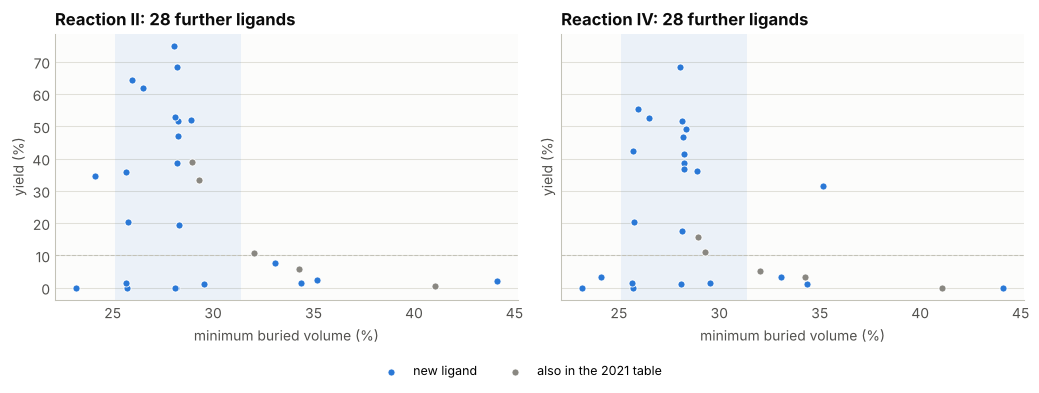

In [3]:
ZENODO = ("https://zenodo.org/api/records/15652094/files/nsf-c-cas/"
          "analysis-for-mapping-of-ni-catalyzed-suzuki-miyaura-couplings-data-v1.zip/content")  # fmt: skip
PDF = os.path.join(CACHE, "lesueur2024_si.pdf")
if not os.path.exists(PDF):
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(ZENODO, timeout=300).read()))
    open(PDF, "wb").write(z.read([n for n in z.namelist() if n.endswith(".pdf")][0]))
SI = "\n".join(p.extract_text() for p in pypdf.PdfReader(PDF).pages)
NUM = r"(-?\d+(?:\.\d+)?|-)"


def si_table(start, end, n_values):
    # rows of a table of the supporting information: identifier, ligand name, then numbers
    a = SI.index(start)
    rows = []
    for line in SI[a : SI.index(end, a + 10)].splitlines():
        m = re.match(r"\s*(\d+)\s+(.+?)" + (r"\s+" + NUM) * n_values + r"\s*$", line)
        if m:
            rows.append(
                [int(m[1]), m[2].strip()]
                + [np.nan if v == "-" else float(v) for v in m.groups()[2:]]
            )
    return pd.DataFrame(rows)


cols = ["id", "ligand", "yield", "V_min", "vbur_printed"]
val = pd.concat([
    si_table("Table S8. Compiled", "Table S9. Compiled", 3).set_axis(cols, axis=1).assign(reaction="II"),
    si_table("Table S9. Compiled", "Figure S13", 3).set_axis(cols, axis=1).assign(reaction="IV"),
])  # fmt: skip
KID = pd.read_csv(OCHEM + "kraken/kraken.csv").drop_duplicates("id").set_index("id")
val["vbur"] = val.id.map(KID.vbur_vbur_min) * 100 / SPHERE
val["active"] = val["yield"] >= 10
val["inside"] = val.vbur.between(LO, HI)
cliff = pd.read_csv(OCHEM + "Vbur/rxns/smiles.csv")
seen = set(cliff.ligand_smiles.map(canon))
val["new"] = ~val.id.map(KID.can_smiles).map(canon).isin(seen)
print(f"{val.id.nunique()} ligands in each of {val.reaction.nunique()} reactions; "
      f"{val[val.new].id.nunique()} are not among the {len(seen)} phosphines of the cliff table")  # fmt: skip


def window_pairs(v, label):
    L = v.groupby("id").agg(vbur=("vbur", "first"), activity=("active", "mean"))
    a, b, p = window_test(L, label)
    found = (v.inside & v.active).sum() / v.active.sum()
    rejected = (~v.inside & ~v.active).sum() / (~v.active).sum()
    print(f"   over {len(v)} ligand-reaction pairs: {found:.0%} of the active ones are inside the window, "
          f"{rejected:.0%} of the inactive ones outside; balanced accuracy {(found + rejected) / 2:.2f}")  # fmt: skip
    return a, b, p, (found + rejected) / 2


a, b, p, ba = window_pairs(val[val.new], "new ligands")
window_pairs(val, "all 28 ligands")
for rx in ("II", "IV"):
    window_pairs(val[val.new & (val.reaction == rx)], f"new ligands, reaction {rx}")
SCORE["H10"] = ("held" if (p < 0.05 and a > b and ba >= 0.65) else "failed",
                f"{val[val.new].id.nunique()} new ligands: activity {a:.2f} inside the window, {b:.2f} outside "
                f"(p = {p:.4f}); balanced accuracy {ba:.2f}")  # fmt: skip
print(SCORE["H10"])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, rx in zip(axes, ("II", "IV")):
    style_axes(ax)
    v = val[val.reaction == rx]
    ax.axvspan(LO, HI, color=SERIES[0], alpha=0.08, linewidth=0)
    ax.axhline(10, color=BASELINE, linewidth=PX, linestyle="--")
    for is_new, color, lab in (
        (True, SERIES[0], "new ligand"),
        (False, MUTED, "also in the 2021 table"),
    ):
        s = v[v.new == is_new]
        ax.scatter(
            s.vbur,
            s["yield"],
            s=26,
            color=color,
            edgecolor="white",
            linewidth=0.6,
            label=lab,
            zorder=3,
        )
    finish_axes(ax, f"Reaction {rx}: 28 further ligands", "minimum buried volume (%)", "yield (%)")
    if ax.get_legend() is not None:
        ax.get_legend().remove()
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels_,
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=9,
    bbox_to_anchor=(0.5, -0.04),
)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### Post hoc: what the window misses

The tables print each ligand's buried volume and electrostatic potential. Three checks that
were not registered: the same test with the buried volumes as printed (one ligand differs from
the kraken file used in this series); the same test with the definition of active under which
the window was actually found; and the paper's own rule, a cut at 57.277 cubic angstrom
(31.9 %) with a second cut on the minimum electrostatic potential.

On the definition: `PROSPECTIVE_TEST.md` fixed "active" as a yield of at least 10 %, "as in
`KAN_Ligand_Reactivity_Cliff`". That is the paper's cut and what the notebook's introduction
said, but its code, and so the window, used a yield of at least a quarter of the best yield
with the same substrate pair. The registered tests used 10 % throughout; the sentence in the
notebook has been corrected.

In [4]:
w = val.assign(vbur=val.vbur_printed * 100 / SPHERE)
w["inside"] = w.vbur.between(LO, HI)
diff = val[(val.vbur - w.vbur).abs() > 0.5].drop_duplicates("id")
print("buried volume differs between the tables and the kraken file for:",
      ", ".join(f"{r.ligand} ({r.vbur:.1f} % in kraken, {r.vbur_printed * 100 / SPHERE:.1f} % printed)" for r in diff.itertuples()))  # fmt: skip
window_pairs(w[w.new], "new ligands, buried volumes as printed")
rel = val.assign(active=val["yield"] >= 0.25 * val.groupby("reaction")["yield"].transform("max"))
print(
    "a quarter of the best yield is",
    ", ".join(
        f"{0.25 * v:.1f} % in reaction {k}"
        for k, v in val.groupby("reaction")["yield"].max().items()
    ),
)
window_pairs(rel[rel.new], "new ligands, active as a quarter of the best yield of the reaction")


def rule_accuracy(v, rule, label):
    found, rejected = (
        (rule & v.active).sum() / v.active.sum(),
        (~rule & ~v.active).sum() / (~v.active).sum(),
    )
    print(f"{label}: {found:.0%} of the active pairs kept, {rejected:.0%} of the inactive ones rejected; "
          f"balanced accuracy {(found + rejected) / 2:.2f}")  # fmt: skip


v = val[val.new]
rule_accuracy(v, v.inside, "the window (25.1 to 31.4 %)")
rule_accuracy(v, v.vbur_printed < 57.277, "the paper's buried-volume cut alone")
rule_accuracy(v, (v.vbur_printed < 57.277) & (v.V_min < -0.046), "the paper's two cuts")
print("ligands inside the window that were inactive in at least one of the two reactions:")
miss = v[v.id.isin(v[v.inside & ~v.active].id)]
display(miss.groupby("id").agg(ligand=("ligand", "first"), buried_volume=("vbur", "first"), V_min=("V_min", "first"),
                               yield_II=("yield", "first"), yield_IV=("yield", "last")).round(3))  # fmt: skip

buried volume differs between the tables and the kraken file for: P(o-OMePh)3 (33.1 % in kraken, 30.1 % printed)
new ligands, buried volumes as printed: 18 ligands inside the window, mean activity 0.694; 5 outside, 0.200; one-sided Mann-Whitney p = 0.0159
   over 46 ligand-reaction pairs: 93% of the active ones are inside the window, 42% of the inactive ones outside; balanced accuracy 0.67
a quarter of the best yield is 18.8 % in reaction II, 17.1 % in reaction IV
new ligands, active as a quarter of the best yield of the reaction: 17 ligands inside the window, mean activity 0.735; 6 outside, 0.167; one-sided Mann-Whitney p = 0.0047
   over 46 ligand-reaction pairs: 93% of the active ones are inside the window, 53% of the inactive ones outside; balanced accuracy 0.73
the window (25.1 to 31.4 %): 93% of the active pairs kept, 53% of the inactive ones rejected; balanced accuracy 0.73
the paper's buried-volume cut alone: 96% of the active pairs kept, 26% of the inactive ones rejected; bala

,ligand,buried_volume,V_min,yield_II,yield_IV
id,,,,,
16,P(4-CF3Ph)3,28.162,-0.022,0.0,17.7
54,"P(2-furyl)3, TFP",25.697,-0.040,0.0,0.0
232,"P(3,5-CF3Ph)3",28.116,-0.004,0.0,1.3
472,P(pyrrolidinyl)3,29.560,-0.062,1.0,1.5
728,Ph2P(CH2)3Si(OEt)3,25.649,-0.051,1.5,1.4


### Post hoc: the fitted equation on the new ligands

The window is one number read off a model. The model itself can be put to the same ligands:
the equation chosen for a new ligand, fitted once on the 450 reactions of the 90 phosphines
(matched to kraken as in `KAN_Ligand_Reactivity_Cliff`), predicts the 23 new ligands in the
two reactions. Not registered, and the bench reactions run somewhat hotter than the plates the
model was trained on (the paper gives plate yield = 0.88 x bench yield - 8.8), so the
probabilities are not expected to be calibrated.

In [5]:
def plain(s):
    m = Chem.MolFromSmiles(str(s))
    return Chem.MolToSmiles(m) if m is not None else None


kr = pd.read_csv(OCHEM + "kraken/kraken.csv")
kr["key"] = kr["ligand"].astype(str).str.lower().str.strip()
kr["plain"] = kr["can_smiles"].where(kr["can_smiles"].notna()).map(plain)
kr = kr.drop_duplicates("key")
cliff["key"], cliff["plain"] = (
    cliff.ligand_name.str.lower().str.strip(),
    cliff.ligand_smiles.map(plain),
)
by_name = cliff.merge(kr, on="key", how="left", suffixes=("", "_k"))
missing = by_name["id"].isna()
by_smi = cliff[missing].merge(
    kr.drop_duplicates("plain"), on="plain", how="left", suffixes=("", "_k")
)
tr = pd.concat([by_name[~missing], by_smi]).reset_index(drop=True)
tr = tr[tr["id"].notna()].reset_index(drop=True)
D_tr = pd.DataFrame({k: tr[c].astype(float).to_numpy() * s for k, (c, s) in KRAKEN.items()})
kept, _ = prune_collinear(
    D_tr.to_numpy(float), list(D_tr.columns), 0.85, keep_first=["pct_Vbur_min"]
)
PAIR = {
    "II": "ClC1=CC=C(OC)C=C1 + OB(O)C1=CC=C(C(F)(F)F)C=C1",
    "IV": "ClC1=CC=C(OC)C=C1 + OB(O)C1=CC=C(C(OCC)=O)C=C1",
}
pair_tr = tr.chloride_smiles + " + " + tr.boronic_acid_smiles
levels = sorted(pair_tr.unique())
assert set(PAIR.values()) <= set(levels)


def design(desc, pairs):
    flags = pd.DataFrame(
        {f"rxn: {lv}": (np.asarray(pairs) == lv).astype(float) for lv in levels[1:]}
    )
    return pd.concat([desc[kept].reset_index(drop=True), flags], axis=1)


# active as in the series: at least a quarter of the best yield with the same substrate pair
y_tr = (tr["yield"] >= 0.25 * tr.groupby(pair_tr)["yield"].transform("max")).to_numpy(float)
X_tr, g_tr = design(D_tr, pair_tr), tr["key"].to_numpy()
new = rel[rel.new].reset_index(drop=True)
D_new = pd.DataFrame({k: KID.loc[new.id, c].to_numpy(float) * s for k, (c, s) in KRAKEN.items()})
X_new = design(D_new, new.reaction.map(PAIR))
print(
    f"trained on {len(X_tr)} reactions of {len(np.unique(g_tr))} ligands; predicting {len(X_new)} ligand-reaction pairs"
)
eq = PieceModel(family="binomial", select_on=NewGroups(g_tr, "new ligand")).fit(X_tr, y_tr)
print(eq.equation())


def deviance(y, p):
    p = np.clip(p, 1e-3, 1 - 1e-3)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).sum())


def report(p, label):
    hit = p >= 0.5
    ba = 0.5 * (
        (hit & (y_new == 1)).sum() / (y_new == 1).sum()
        + (~hit & (y_new == 0)).sum() / (y_new == 0).sum()
    )
    skill = 1 - deviance(y_new, p) / deviance(y_new, np.full(len(y_new), y_tr.mean()))
    print(f"   {label}: skill {skill:+.2f} against the training mean, balanced accuracy {ba:.2f}")


p_eq = eq.predict(X_new)
p_cu = np.asarray(eq.source_.predict(eq.design_.transform(X_new)), float)
for label, y_new in (("active as in the series (a quarter of the best yield)", new.active.to_numpy(float)),
                     ("active as registered (yield of at least 10 %)", (new["yield"] >= 10).to_numpy(float))):  # fmt: skip
    print(label)
    report(p_eq, "equation chosen for a new ligand")
    report(p_cu, "curves tuned for a new ligand")
    report(np.where(new.inside, 0.9, 0.1), "the window as a rule (0.9 inside, 0.1 outside)")

trained on 450 reactions of 90 ligands; predicting 46 ligand-reaction pairs
pieces:
  p0 = W(pct_Vbur_min; 25.1, 31.4, 1.58)   [1 inside 25.1 to 31.4]
  p1 = |V_min + 0.0586| / 0.0121
  p2 = (V_min + 0.055) / 0.0121
  p3 = [rxn: ClC1=CC=C(OC)C=C1 + OB(O)C1=CC=C(C(OCC)=O)C=C1]  (0 or 1)
  p4 = [rxn: ClC1=CC=C(OC)C=C1 + OB(O)C1=C(C)C=C(C)C=C1C]  (0 or 1)
  p5 = [rxn: ClC1=CC=C(OC)C=C1 + OB(O)C1=CC=CC=C1]  (0 or 1)
  p6 = [rxn: ClC1=CC=C(OC)C=C1 + OB(O)C1=CC=C(C(F)(F)F)C=C1]  (0 or 1)
log-odds(y) = -0.6619 +6.982*p0 -2.731*p1 -0.3344*p2 -4.073*p3 -8.311*p4 -4.885*p5 -2.038*p6 +8.195*p0*p4 +2.909*p0*p5 -0.1333*p0*p6
  where W(x; a, b, w) = S((x - a) / w) - S((x - b) / w), 1 between a and b
active as in the series (a quarter of the best yield)
   equation chosen for a new ligand: skill -0.20 against the training mean, balanced accuracy 0.64
   curves tuned for a new ligand: skill -0.02 against the training mean, balanced accuracy 0.71
   the window as a rule (0.9 inside, 0.1 outside): skill

### Post hoc: would the 90 ligands alone have said "carry the rule, not the equation"?

The rule above was given its two probabilities by hand. `transfer_ledger(..., rule=True)`
(added to `transferledger` after this result) puts the question to the 90 ligands themselves: a
rung below the equation holds the best statement about one variable, a cut or a window, chosen
and scored on held-out ligands like the equation. The rule it fits on the 90 is then scored on
the 23 new ligands, with the probabilities it learned.

In [6]:
ledger_90, _ = step("ledger_90", lambda: transfer_ledger(
    X_tr, y_tr, NewGroups(g_tr, "new ligand"), family="binomial", rule=True, n_repeats=3, n_jobs=N_JOBS))  # fmt: skip
print(ledger_90.ladder_text().to_string())
one = ledger_90.models["one rule, chosen for new ligand"]
print("\nthe rule chosen for a new ligand, fitted on the 90:")
print(one.equation())
p_one = one.predict(X_new)
for label, y_new in (("active as in the series (a quarter of the best yield)", new.active.to_numpy(float)),
                     ("active as registered (yield of at least 10 %)", (new["yield"] >= 10).to_numpy(float))):  # fmt: skip
    print(label)
    report(p_one, "one rule, fitted on the 90")
    report(p_eq, "equation chosen for a new ligand")

scheme                                      reference            new ligand
rung                                                                       
baseline (training mean)         0.000 [0.000, 0.000]  0.000 [0.000, 0.000]
one rule                         0.157 [0.099, 0.216]  0.135 [0.046, 0.223]
one rule, chosen for new ligand  0.160 [0.099, 0.220]  0.138 [0.048, 0.229]
equation                         0.343 [0.244, 0.441]  0.293 [0.164, 0.422]
equation, chosen for new ligand  0.354 [0.261, 0.448]  0.316 [0.189, 0.442]
curves                           0.520 [0.437, 0.603]  0.418 [0.281, 0.555]
curves, tuned for new ligand     0.524 [0.450, 0.599]  0.448 [0.348, 0.549]

the rule chosen for a new ligand, fitted on the 90:
pieces:
  p0 = W(pct_Vbur_min; 25.1, 31.4, 1.58)   [1 inside 25.1 to 31.4]
log-odds(y) = -3.066 +4.273*p0
  where W(x; a, b, w) = S((x - a) / w) - S((x - b) / w), 1 between a and b
active as in the series (a quarter of the best yield)
   one rule, fitted on the 9

### Post hoc: where the equation lost

The equation holds three kinds of term: the window, the electrostatic potential, and one offset
per reaction (with its product with the window). Which of them failed on the new ligands? Split
by reaction, with the share of in-window ligands that are active in the 2021 table and among
the new ligands, and `support()`, which says whether a new row lies outside what the equation
was fitted on.

In [7]:
y_new = new.active.to_numpy(float)
sup = eq.support(X_new)
print(
    f"new rows outside the range of the 90 in a variable of the equation: {int((sup.outside > 0).sum())} of {len(sup)}"
)
in_tr, in_new = X_tr["pct_Vbur_min"].between(25.1, 31.4).to_numpy(), new.inside.to_numpy()
rows = []
for rx, lv in PAIR.items():
    m_tr, m = (pair_tr == lv).to_numpy(), (new.reaction == rx).to_numpy()
    base = deviance(y_new[m], np.full(m.sum(), y_tr.mean()))
    rows.append({"reaction": rx,
                 "active in the window, 2021 table": f"{y_tr[m_tr & in_tr].mean():.2f} ({(m_tr & in_tr).sum()} ligands)",
                 "active in the window, new ligands": f"{y_new[m & in_new].mean():.2f} ({(m & in_new).sum()} ligands)",
                 "the equation's mean prediction there": f"{p_eq[m & in_new].mean():.2f}",
                 "skill, equation": f"{1 - deviance(y_new[m], p_eq[m]) / base:+.2f}",
                 "skill, one rule": f"{1 - deviance(y_new[m], p_one[m]) / base:+.2f}"})  # fmt: skip
display(pd.DataFrame(rows).set_index("reaction").T)

new rows outside the range of the 90 in a variable of the equation: 2 of 46


reaction,II,IV
"active in the window, 2021 table",0.50 (48 ligands),0.25 (48 ligands)
"active in the window, new ligands",0.71 (17 ligands),0.76 (17 ligands)
the equation's mean prediction there,0.48,0.20
"skill, equation",+0.36,-0.75
"skill, one rule",+0.27,+0.25


## 2. H11: for Pd the active side is above the cut

The same supporting information reprints yields for eight Pd-catalysed reactions with kraken
monophosphines (Tables S3 to S7: reactions VI to IX are four cross-couplings, X a
Suzuki-Miyaura coupling, XI and XIII Heck reactions, XII a C(sp3)-H arylation).

*H11*: in more than half of the reactions that have at least 5 active and 5 inactive ligands, a
single cut of minimum buried volume between 28 and 34 %, with the active ligands above it, has a
balanced accuracy over ligands above 0.65.

,ligands,active,inactive,active above,cut (%),active below
reaction,,,,,,
VI,55,29,26,0.63,28.2,0.57
VII,53,27,26,0.85,30.0,0.37
VIII,30,20,10,0.88,30.8,0.35
IX,28,15,13,0.92,30.8,0.38
X,30,30,0,not testable,not testable,not testable
XI,71,39,32,0.66,33.0,0.42
XII,79,75,4,not testable,not testable,not testable
XIII,14,7,7,0.57,31.7,0.57


('held', 'active above the cut with balanced accuracy over 0.65 in 4 of 6 testable Pd reactions (VII, VIII, IX, XI)')


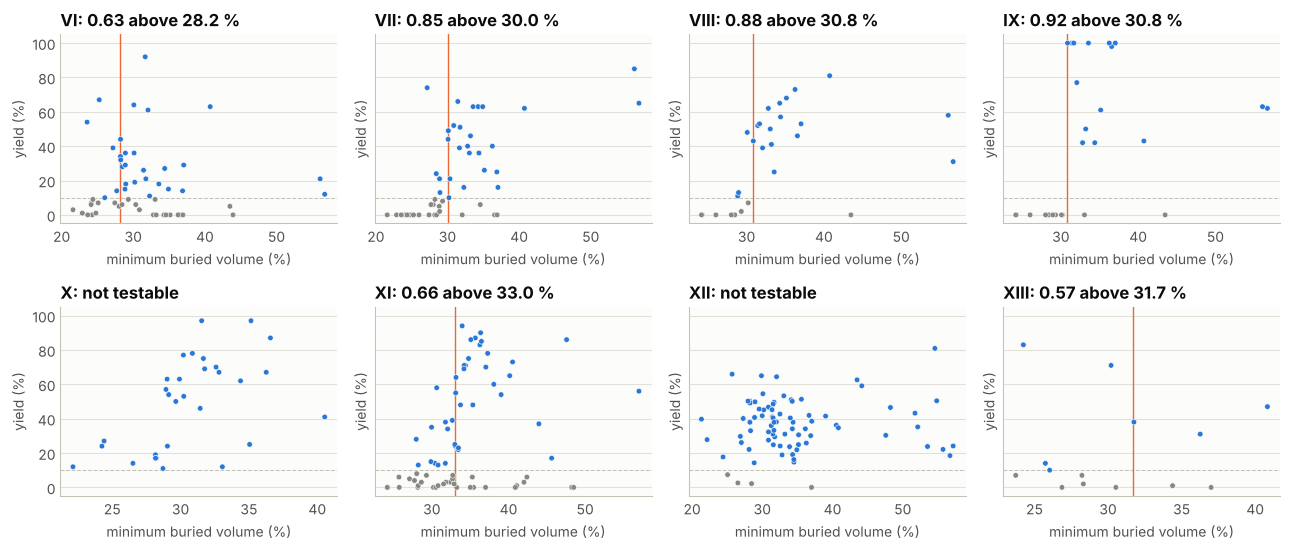

In [8]:
pd_tables = pd.concat([
    si_table("Table S3. Reaction yields", "As shown below", 4).set_axis(["id", "ligand", "VI", "VII", "VIII", "IX"], axis=1)
    .melt(["id", "ligand"], var_name="reaction", value_name="yield"),
    si_table("Table S4. Reaction yields", "Table S5. Reaction yields", 1).set_axis(["id", "ligand", "yield"], axis=1).assign(reaction="X"),
    si_table("Table S5. Reaction yields", "Table S6. Reaction yields", 1).set_axis(["id", "ligand", "yield"], axis=1).assign(reaction="XI"),
    si_table("Table S6. Reaction yields", "Table S7. Reaction yields", 1).set_axis(["id", "ligand", "yield"], axis=1).assign(reaction="XII"),
    si_table("Table S7. Reaction yields", "results from the complete dataset", 1).set_axis(["id", "ligand", "yield"], axis=1).assign(reaction="XIII"),
]).dropna(subset=["yield"])  # fmt: skip
pd_tables["vbur"] = pd_tables.id.map(KID.vbur_vbur_min) * 100 / SPHERE
pd_tables = pd_tables.dropna(subset=["vbur"])
pd_tables["active"] = pd_tables["yield"] >= 10
CUTS = np.round(np.arange(28, 34.01, 0.1), 1)
ORDER = ["VI", "VII", "VIII", "IX", "X", "XI", "XII", "XIII"]


def cut_accuracy(v, side):
    best = (0.0, None)
    for c in CUTS:
        rule = v.vbur > c if side == "above" else v.vbur <= c
        acc = 0.5 * (
            (rule & v.active).sum() / v.active.sum() + (~rule & ~v.active).sum() / (~v.active).sum()
        )
        best = max(best, (acc, c))
    return best


rows = []
for rx in ORDER:
    v = pd_tables[pd_tables.reaction == rx]
    row = {
        "reaction": rx,
        "ligands": len(v),
        "active": int(v.active.sum()),
        "inactive": int((~v.active).sum()),
    }
    if min(row["active"], row["inactive"]) >= 5:
        (row["active above"], row["cut (%)"]), (row["active below"], _) = (
            cut_accuracy(v, "above"),
            cut_accuracy(v, "below"),
        )
    rows.append(row)
pd_cuts = pd.DataFrame(rows).set_index("reaction")
display(pd_cuts.round(2).astype(object).fillna("not testable"))
ok = pd_cuts.dropna(subset=["active above"])
n_ok = int((ok["active above"] > 0.65).sum())
SCORE["H11"] = ("held" if n_ok > len(ok) / 2 else "failed",
                f"active above the cut with balanced accuracy over 0.65 in {n_ok} of {len(ok)} testable Pd reactions "
                f"({', '.join(ok.index[ok['active above'] > 0.65])})")  # fmt: skip
print(SCORE["H11"])

fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
for ax, rx in zip(axes.ravel(), ORDER):
    style_axes(ax)
    v = pd_tables[pd_tables.reaction == rx]
    ax.axhline(10, color=BASELINE, linewidth=PX, linestyle="--")
    ax.scatter(
        v.vbur,
        v["yield"],
        s=16,
        color=np.where(v.active, SERIES[0], MUTED),
        edgecolor="white",
        linewidth=0.4,
        zorder=3,
    )
    title = f"{rx}: not testable"
    if rx in ok.index:
        ax.axvline(ok.loc[rx, "cut (%)"], color=SERIES[1], linewidth=1.0)
        title = f"{rx}: {ok.loc[rx, 'active above']:.2f} above {ok.loc[rx, 'cut (%)']:.1f} %"
    finish_axes(ax, title, "minimum buried volume (%)", "yield (%)")
    if ax.get_legend() is not None:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

## 3. H3 to H6 again, with the repaired fit

What went wrong. A yes/no model is fitted by repeating a weighted least-squares step. Where
some conditions never give product, the score of those reactions runs toward minus infinity,
the weights of the step collapse, and a full step overshoots: the fit then alternates between
two states, both far worse than the training mean. On the Ni reactions the registered run shows
it in the curves rung, -2.8 on random folds and -5.6 for a new ligand, while the equation rung,
whose weights are fitted separately, stood at 0.30. Version 0.2 takes the largest fraction of
each step that does not raise the penalized deviance. Fits that had converged are unchanged.

The cells below are the registered ones, unchanged, on the same rows and seeds. Nothing else
differs from `KAN_Prospective_Test` but the library version.

### The Cernak table

Downloaded from the Open Reaction Database. The API returns at most 1000 reaction ids per
search, so the search is split by ligand (and, where needed, by aryl halide, amine, temperature,
base and catalyst), then the reactions are downloaded 1000 at a time. Reactions run without a
ligand cannot be reached by a per-ligand search and are not needed here.

In [9]:
from ord_schema.proto import dataset_pb2, reaction_pb2

API = "https://open-reaction-database.org/api"
DID = "ord_dataset-805ad863feef48579d95d86a728035f4"
PB = os.path.join(CACHE, "cernak_cn.pb.gz")


def post(path, body, tries=6):
    for k in range(tries):
        try:
            req = urllib.request.Request(API + path, data=json.dumps(body).encode(),
                                         headers={"content-type": "application/json"})  # fmt: skip
            with urllib.request.urlopen(req, timeout=300) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 422:
                raise RuntimeError(e.read()[:300])
            time.sleep(5 * 2**k)
        except Exception:
            time.sleep(5 * 2**k)
    raise RuntimeError(path)


def ident(v):
    inner = {"op": "eq", "path": "value", "value": {"literal": v}}
    return {"op": "exists", "path": "inputs.components",
            "where": {"op": "exists", "path": "identifiers", "where": inner}}  # fmt: skip


def temp(c):
    k = c + 273.15
    return {"op": "and", "clauses": [
        {"op": "ge", "path": "conditions.temperature.setpoint_kelvin", "value": {"literal": k - 1}},
        {"op": "le", "path": "conditions.temperature.setpoint_kelvin", "value": {"literal": k + 1}}]}  # fmt: skip


def search(clauses):
    where = {
        "op": "and",
        "clauses": [{"op": "eq", "path": "dataset_id", "value": {"literal": DID}}] + clauses,
    }
    return json.loads(post("/search", {"query": {"where": where, "limit": 1000}}))["reaction_ids"]


LEVELS = [[ident(f"E{i}") for i in range(1, 7)], [ident(f"N{i}") for i in range(1, 4)],
          [temp(t) for t in (25, 30, 60, 80, 100)], [ident(f"B{i}") for i in range(25)],
          [ident(f"C{i}") for i in range(45)]]  # fmt: skip


def walk(clauses, depth, ids):
    got = search(clauses)
    if len(got) < 1000 or depth == len(LEVELS):
        ids.update(got)
        return
    for c in LEVELS[depth]:
        walk(clauses + [c], depth + 1, ids)


if not os.path.exists(PB):
    t0, ids = time.time(), set()
    for k in range(260):
        walk([ident(f"L{k}")], 0, ids)
    full, idl = dataset_pb2.Dataset(dataset_id=DID), sorted(ids)
    for i in range(0, len(idl), 1000):
        raw = post("/download", {"reaction_ids": idl[i : i + 1000]})
        full.reactions.extend(dataset_pb2.Dataset.FromString(gzip.decompress(raw)).reactions)
    open(PB, "wb").write(gzip.compress(full.SerializeToString()))
    print(f"downloaded {len(full.reactions)} reactions in {time.time() - t0:.0f} s")
ds = dataset_pb2.Dataset.FromString(gzip.decompress(open(PB, "rb").read()))

SMI, NAME = reaction_pb2.CompoundIdentifier.SMILES, reaction_pb2.CompoundIdentifier.NAME
YIELD = reaction_pb2.ProductMeasurement.YIELD
rows = []
for r in ds.reactions:
    row = {}
    for key, inp in r.inputs.items():
        role = key.replace(" soln", "")
        for c in inp.components:
            idx = [x.value for x in c.identifiers if "ChemTypeIdx" in x.details]
            smi = [x.value for x in c.identifiers if x.type == SMI]
            nm = [x.value for x in c.identifiers if x.type == NAME]
            if idx and idx[0].startswith("S"):  # a solvent of a stock solution
                row.setdefault("solvents", set()).add(nm[0] if nm else smi[0])
                continue
            row[f"{role}_id"], row[f"{role}_smiles"] = (idx or [None])[0], (smi or [None])[0]
            row[f"{role}_name"] = (nm or [None])[0]
    t = r.conditions.temperature.setpoint
    row["temperature_C"] = t.value if t.units == 1 else t.value - 273.15
    row["yield"] = [
        m.percentage.value
        for o in r.outcomes
        for p in o.products
        for m in p.measurements
        if m.type == YIELD
    ][0]
    row["solvents"] = "+".join(sorted(row.get("solvents", [])))
    rows.append(row)
cn = pd.DataFrame(rows)
cn["metal"] = cn.catalyst_smiles.map(
    lambda s: next((m for m in ("Pd", "Ni", "Cu") if m in str(s)), "none")
)
lig = cn[["ligand_id", "ligand_smiles"]].drop_duplicates("ligand_id")
lig = lig.assign(csmi=lig.ligand_smiles.map(canon))
cn = cn.merge(lig[["ligand_id", "csmi"]], on="ligand_id", how="left")
cn["in_kraken"] = cn.csmi.isin(K.index)
cn["active"] = cn["yield"] >= 10
print(
    f"{len(cn)} reactions, {cn.ligand_id.nunique()} ligands, {cn[cn.in_kraken].csmi.nunique()} of them monodentate phosphines in kraken"
)
display(cn.groupby("metal").agg(reactions=("active", "size"), with_kraken_ligand=("in_kraken", "sum"),
                                kraken_ligands=("csmi", lambda s: s[cn.loc[s.index, "in_kraken"]].nunique())))  # fmt: skip

49632 reactions, 154 ligands, 53 of them monodentate phosphines in kraken


,reactions,with_kraken_ligand,kraken_ligands
metal,,,
Cu,15792,4064,53
Ni,12032,6560,52
Pd,10340,5476,52
none,11468,2300,53


In [10]:
d = cn[cn.in_kraken & cn.metal.isin(["Ni", "Pd", "Cu"])].copy()
d["vbur"] = d.csmi.map(K["pct_Vbur_min"])
REGISTERED = {  # as scored in KAN_Prospective_Test with transferledger 0.1.0
    "H3": ("failed", "equation chosen for a new ligand: skill 0.29 [0.27, 0.32]; steric descriptors kept: none"),
    "H4": ("held", "mean error of the predicted rates -0.15; the law asked for at least the ligands that were enough "
                   "in 53% of 15 comparisons"),
    "H5": ("held", "established at 22 ligands in 1 of 16 checks; skill with 44 at or above the floor in 100%"),
    "H6": ("held", "spread out better than random in 19% of draws (curves)"),
}  # fmt: skip

### H3: the gate on the Ni reactions

In [11]:
ni = d[d.metal == "Ni"].reset_index(drop=True)
LIG = ligand_descriptors(ni.csmi)
COND = pd.concat([onehot(ni.catalyst_name, "catalyst"), onehot(ni.base_name, "base"), onehot(ni.solvents, "solvent"),
                  onehot(ni.electrophile_name, "aryl halide"), onehot(ni.nucleophile_name, "amine"),
                  onehot(ni.temperature_C.astype(int), "temperature")], axis=1)  # fmt: skip
Xn = pd.concat([LIG, COND], axis=1)
yn = ni.active.to_numpy(float)
gn = ni.ligand_name.to_numpy()
print(Xn.shape, "ligand variables:", list(LIG.columns))
STERIC = {
    "pct_Vbur_min",
    "pct_Vbur_Boltz",
    "pct_Vbur_max",
    "Sterimol_B1",
    "Sterimol_B5",
    "Sterimol_L",
}

ledger, took = step("ledger_ni", lambda: transfer_ledger(
    Xn, yn, {"new ligand": NewGroups(gn, "new ligand")}, model=PieceModel(family="binomial"),
    family="binomial", blocks={"ligand": list(LIG.columns), "conditions": list(COND.columns)},
    n_repeats=2, n_jobs=N_JOBS))  # fmt: skip
print(ledger)
print(f"({took:.0f} s)")
chosen, _ = step("chosen_ni", lambda: PieceModel(family="binomial", select_on=NewGroups(gn, "new ligand")).fit(Xn, yn))  # fmt: skip
print(chosen.equation())
row = ledger.skill[
    (ledger.skill.rung == "equation, chosen for new ligand") & (ledger.skill.scheme == "new ligand")
].iloc[0]
steric = sorted(STERIC & set(chosen.variables_))
h3 = bool(steric) and row.lo > 0
SCORE["H3"] = ("held" if h3 else "failed",
               f"equation chosen for a new ligand: skill {row.skill:.2f} [{row.lo:.2f}, {row.hi:.2f}]; "
               f"steric descriptors kept: {', '.join(steric) or 'none'}")  # fmt: skip
print(SCORE["H3"])

(6560, 42) ligand variables: ['pct_Vbur_min', 'pct_Vbur_Boltz', 'Sterimol_B1', 'Sterimol_B5', 'Sterimol_L', 'E_HOMO', 'E_LUMO', 'V_min', 'NBO_charge_P', 'pyramidalization_P', 'dipole']
Skill: share of the baseline's loss removed, on held-out rows (5 folds x 2 repeats; 95 % intervals over units)
scheme                                      reference            new ligand
rung                                                                       
baseline (training mean)         0.000 [0.000, 0.000]  0.000 [0.000, 0.000]
equation                         0.598 [0.570, 0.626]  0.589 [0.555, 0.624]
equation, chosen for new ligand  0.599 [0.571, 0.626]  0.589 [0.555, 0.624]
curves                           0.556 [0.528, 0.584]  0.506 [0.463, 0.549]
curves, tuned for new ligand     0.556 [0.528, 0.583]  0.552 [0.519, 0.586]

Memorized: reference skill given up when variables must earn their place under the shift
            memorized     lo     hi
shift                              
new ligand

### H4 to H6: the planning tools, 24 reactions per ligand

In [12]:
rng = np.random.default_rng(0)
keep = np.sort(
    np.concatenate([rng.permutation(np.flatnonzero(gn == u))[:24] for u in np.unique(gn)])
)
Xt = Xn.iloc[keep].reset_index(drop=True)
Xt = Xt.loc[:, Xt.std() > 0]
yt, gt = yn[keep], gn[keep]
labels = np.unique(gt)
print(len(Xt), "rows,", len(labels), "ligands")

1248 rows, 52 ligands


In [13]:
SHARES, REVEAL = (0.2, 0.35, 0.5, 0.7, 0.9), [26, 40, 52]
took = 0.0
truth, s = step("h4_truth", lambda: detectable(
    Xt, yt, NewGroups(gt, "new ligand"), family="binomial", sizes=REVEAL, shares=SHARES,
    n_trials=12, n_jobs=N_JOBS, random_state=99))  # fmt: skip
took += s
print(truth)
measured = truth.power.set_index(["shape", "units", "share"])["detected"]
rng = np.random.default_rng(0)
rows, needs = [], []
for trial in range(3):
    sub = np.flatnonzero(np.isin(gt, rng.choice(labels, 20, replace=False)))
    D, s = step(f"h4_law_{trial}", lambda: detectable(
        Xt.iloc[sub].reset_index(drop=True), yt[sub], NewGroups(gt[sub], "new ligand"), family="binomial",
        shares=SHARES, n_trials=12, horizon=100.0, n_jobs=N_JOBS, random_state=trial))  # fmt: skip
    took += s
    for shape, m, q in measured.index:
        rows.append({"trial": trial, "shape": shape, "units": m, "share": q,
                     "predicted": float(D.rate(m, q, shape)), "measured": float(measured.loc[(shape, m, q)])})  # fmt: skip
    for shape in ("trend", "peak"):
        for q in SHARES:
            needs.append({"trial": trial, "shape": shape, "share": q, "needed": D.needed(q, shape)})
check = pd.DataFrame(rows).assign(error=lambda c: c.predicted - c.measured)
display(check.groupby(["shape", "units"]).agg(predicted=("predicted", "mean"), measured=("measured", "mean"),
                                              error=("error", "mean")).round(2))  # fmt: skip
needs = pd.DataFrame(needs)
cmp = []
for (shape, q), c in truth.power.groupby(["shape", "share"]):
    hit = c[c.detected >= 0.8].units
    if len(hit):
        for v in needs[(needs["shape"] == shape) & (needs.share == q)].needed:
            cmp.append({"shape": shape, "share": q, "enough": int(hit.min()),
                        "law asked for": np.inf if v is None or pd.isna(v) else int(v)})  # fmt: skip
cmp = pd.DataFrame(cmp)
display(cmp)
me = check.error.mean()
ok = (cmp["law asked for"] >= cmp["enough"]).mean() if len(cmp) else float("nan")
h4 = me <= 0.05 and (len(cmp) == 0 or ok >= 0.5)
SCORE["H4"] = ("held" if h4 else "failed",
               f"mean error of the predicted rates {me:+.2f}; the law asked for at least the ligands that were enough in "
               f"{ok:.0%} of {len(cmp)} comparisons")  # fmt: skip
print(SCORE["H4"], f"({took:.0f} s)")

How often a planted property of each share was established (52 ligands in hand; 'established' means in 80 % of trials)
share        0.20  0.35  0.50  0.70  0.90
shape units                              
peak  26     0.00  0.00  0.42  0.25  0.83
      40     0.08  0.17  0.42  0.50  1.00
      52     0.25  0.58  0.50  0.92  1.00
trend 26     0.17  0.33  0.75  1.00  1.00
      40     0.17  0.33  0.50  1.00  1.00
      52     0.08  0.25  0.75  1.00  1.00

A property that captures nothing was admitted in 0% of trials (trend, 26 ligands), 0% of trials (trend, 40 ligands), 8% of trials (trend, 52 ligands), 17% of trials (peak, 26 ligands), 0% of trials (peak, 40 ligands), 0% of trials (peak, 52 ligands)

trend: with 52 ligands a property must capture at least 54% of the differences between ligands to be established
peak: with 52 ligands a property must capture at least 63% of the differences between ligands to be established

Ligands needed for a weaker property:
                30 % 50 % 70 

predicted  measured  error
shape units                            
peak  26          0.32      0.30   0.02
      40          0.40      0.43  -0.04
      52          0.45      0.65  -0.20
trend 26          0.58      0.65  -0.07
      40          0.67      0.60   0.07
      52          0.72      0.62   0.11

,shape,share,enough,law asked for
0,peak,0.7,52,93
1,peak,0.7,52,73
2,peak,0.7,52,74
3,peak,0.9,26,26
4,peak,0.9,26,21
5,peak,0.9,26,21
6,trend,0.7,26,36
7,trend,0.7,26,28
8,trend,0.7,26,21
9,trend,0.9,26,11


('held', 'mean error of the predicted rates -0.02; the law asked for at least the ligands that were enough in 50% of 12 comparisons') (3831 s)


In [14]:
B, took = step("h5_backtest", lambda: backtest(
    Xt, yt, NewGroups(gt, "new ligand"), have=22, factors=(2.0,), n_trials=8, family="binomial",
    n_jobs=N_JOBS, random_state=0))  # fmt: skip
display(B.round(3))
est = B[B.state == "established"]
if len(est):
    kept = (est.realized >= est.lo).mean()
    SCORE["H5"] = ("held" if kept >= 0.9 else "failed", f"established at 22 ligands in {len(est)} of {len(B)} checks; "
                   f"skill with 44 at or above the floor in {kept:.0%}")  # fmt: skip
else:
    SCORE["H5"] = ("not testable", f"nothing established at 22 ligands in {len(B)} checks")
print(SCORE["H5"], f"({took:.0f} s)")

,trial,have,factor,units,rung,state,held,lo,hi,extended,realized
0,0,22,2.0,44,"equation, chosen for new ligand",nothing yet,0.051,-0.046,0.147,0.059,0.442
1,0,22,2.0,44,"curves, tuned for new ligand",established,0.293,0.137,0.450,0.340,0.447
2,1,22,2.0,44,"equation, chosen for new ligand",established,0.140,0.056,0.225,0.096,0.353
3,1,22,2.0,44,"curves, tuned for new ligand",established,0.392,0.275,0.509,0.347,0.434
4,2,22,2.0,44,"equation, chosen for new ligand",nothing yet,0.045,-0.072,0.162,0.023,0.350
5,2,22,2.0,44,"curves, tuned for new ligand",established,0.277,0.122,0.433,0.388,0.473
6,3,22,2.0,44,"equation, chosen for new ligand",nothing yet,-0.005,-0.221,0.210,-0.032,0.393
7,3,22,2.0,44,"curves, tuned for new ligand",established,0.480,0.308,0.652,0.611,0.374
8,4,22,2.0,44,"equation, chosen for new ligand",nothing yet,0.111,-0.031,0.252,0.230,0.395
9,4,22,2.0,44,"curves, tuned for new ligand",established,0.246,0.073,0.418,0.313,0.468


('held', 'established at 22 ligands in 10 of 16 checks; skill with 44 at or above the floor in 100%') (1424 s)


In [15]:
Zt = Xt[[c for c in LIG.columns if c in Xt]].groupby(gt).mean().loc[labels].to_numpy()
Z = (Zt - Zt.mean(0)) / Zt.std(0)


def farthest(pool, m, rng):
    chosen = [int(rng.choice(pool))]
    dist = np.linalg.norm(Z[pool] - Z[chosen[0]], axis=1)
    while len(chosen) < m:
        k = int(np.argmax(dist))
        chosen.append(int(pool[k]))
        dist = np.minimum(dist, np.linalg.norm(Z[pool] - Z[pool[k]], axis=1))
    return np.array(chosen)


def deviance(y, p):
    p = np.clip(p, 1e-3, 1 - 1e-3)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).sum())


def skill_of(train, test):
    tr, te = np.flatnonzero(np.isin(gt, train)), np.flatnonzero(np.isin(gt, test))
    if np.ptp(yt[tr]) == 0:
        return 0.0, 0.0
    m = PieceModel(family="binomial", select_on=NewGroups(gt[tr], "new ligand")).fit(
        Xt.iloc[tr].reset_index(drop=True), yt[tr]
    )
    p0 = np.full(len(te), yt[tr].mean())
    cu = np.asarray(m.source_.predict(m.design_.transform(Xt.iloc[te])), float)
    return 1 - deviance(yt[te], m.predict(Xt.iloc[te])) / deviance(yt[te], p0), 1 - deviance(
        yt[te], cu
    ) / deviance(yt[te], p0)


rng, jobs = np.random.default_rng(0), []
for draw in range(12):
    perm = rng.permutation(len(labels))
    test, pool = perm[:13], perm[13:]
    for m in (13, 20, 30):
        jobs.append(
            (m, draw, "at random", labels[rng.choice(pool, m, replace=False)], labels[test])
        )
        jobs.append((m, draw, "spread out", labels[farthest(pool, m, rng)], labels[test]))
out, took = step("h6_spread", lambda: Parallel(n_jobs=N_JOBS)(delayed(skill_of)(tr, te) for *_, tr, te in jobs))  # fmt: skip
S = pd.DataFrame([{"units": m, "draw": dr, "chosen": h, "equation": e, "curves": c}
                  for (m, dr, h, _, _), (e, c) in zip(jobs, out)])  # fmt: skip
W = S.pivot_table(index=["units", "draw"], columns="chosen", values="curves")
display(S.groupby(["units", "chosen"])[["equation", "curves"]].median().round(3))
better = (W["spread out"] > W["at random"]).mean()
SCORE["H6"] = (
    "held" if better <= 0.6 else "failed",
    f"spread out better than random in {better:.0%} of draws (curves)",
)
print(SCORE["H6"], f"({took:.0f} s)")

equation  curves
units chosen                      
13    at random     -0.129   0.259
      spread out     0.105   0.308
20    at random      0.056   0.322
      spread out     0.102   0.363
30    at random      0.247   0.425
      spread out     0.242   0.423

('held', 'spread out better than random in 50% of draws (curves)') (153 s)


In [16]:
again = pd.DataFrame([{"hypothesis": h, "registered (0.1.0)": f"{REGISTERED[h][0]}: {REGISTERED[h][1]}",
                       "repeated (repaired fit)": f"{SCORE[h][0]}: {SCORE[h][1]}"} for h in ("H3", "H4", "H5", "H6")]).set_index("hypothesis")  # fmt: skip
with pd.option_context("display.max_colwidth", 200):
    display(again)

,registered (0.1.0),repeated (repaired fit)
hypothesis,,
H3,"failed: equation chosen for a new ligand: skill 0.29 [0.27, 0.32]; steric descriptors kept: none","failed: equation chosen for a new ligand: skill 0.59 [0.55, 0.62]; steric descriptors kept: none"
H4,held: mean error of the predicted rates -0.15; the law asked for at least the ligands that were enough in 53% of 15 comparisons,held: mean error of the predicted rates -0.02; the law asked for at least the ligands that were enough in 50% of 12 comparisons
H5,held: established at 22 ligands in 1 of 16 checks; skill with 44 at or above the floor in 100%,held: established at 22 ligands in 10 of 16 checks; skill with 44 at or above the floor in 100%
H6,held: spread out better than random in 19% of draws (curves),held: spread out better than random in 50% of draws (curves)


## 4. Was there anything about a ligand to explain?

`unit_ceiling` scores, on random folds where every ligand is seen in training, the conditions
alone, the conditions plus the ligand's descriptors, and the conditions plus the ligand's
identity. What identity adds is the most any description of a ligand could add. One table per
metal: the reactions of that metal with a kraken phosphine.

In [17]:
def metal_table(m):
    s = d[d.metal == m].reset_index(drop=True)
    L = ligand_descriptors(s.csmi)
    C = pd.concat([onehot(s.catalyst_name, "catalyst"), onehot(s.base_name, "base"), onehot(s.solvents, "solvent"),
                   onehot(s.electrophile_name, "aryl halide"), onehot(s.nucleophile_name, "amine"),
                   onehot(s.temperature_C.astype(int), "temperature")], axis=1)  # fmt: skip
    C = C.loc[:, C.std() > 0]
    return (
        pd.concat([L, C], axis=1),
        s.active.to_numpy(float),
        s.ligand_name.to_numpy(),
        list(L.columns),
        list(C.columns),
    )


CEILINGS, rows = {}, []
for m in ("Ni", "Pd", "Cu"):
    Xm, ym, gm, lig_m, cond_m = metal_table(m)
    C, took = step(f"ceiling_{m}", lambda: unit_ceiling(
        Xm, ym, NewGroups(gm, "new ligand"), family="binomial", describe=lig_m, n_jobs=N_JOBS))  # fmt: skip
    CEILINGS[m] = C
    print(
        f"\n{m}: {len(ym)} reactions, {len(np.unique(gm))} ligands, {ym.mean():.1%} active ({took:.0f} s)"
    )
    print(C)
    row = {"metal": m, "reactions": len(ym), "ligands": len(np.unique(gm)), "state": C.state()}
    for kind, label in (("additive", "additive curves"), ("any", "gradient boosting")):
        r = C.adds[(C.adds.adds == "identity") & (C.adds.kind == kind)].iloc[0]
        row[f"identity adds ({label})"] = f"{r.contribution:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}]"
    row["description reaches"] = "" if C.captured() is None else f"{C.captured():.0%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("metal"))


Ni: 6560 reactions, 52 ligands, 8.7% active (63 s)
Skill on held-out rows of ligands seen in training (95 % intervals over ligands)
kind                              additive                   any
model                                                           
without the unit      0.556 [0.524, 0.588]  0.662 [0.629, 0.695]
with its description  0.556 [0.520, 0.591]  0.615 [0.560, 0.670]
with its identity     0.557 [0.524, 0.591]  0.592 [0.532, 0.653]

Knowing which ligand it is adds +0.001 [-0.006, +0.008] (additive model).
Nothing to explain: once the other variables are known, ligands do not differ by an amount that can be told from zero. No description of a ligand can be tested on this table.

Pd: 5476 reactions, 53 ligands, 6.6% active (48 s)
Skill on held-out rows of ligands seen in training (95 % intervals over ligands)
kind                              additive                   any
model                                                           
without the unit      0.362 [

,reactions,ligands,state,identity adds (additive curves),identity adds (gradient boosting),description reaches
metal,,,,,,
Ni,6560,52,nothing to explain,"+0.001 [-0.006, +0.008]","-0.070 [-0.114, -0.026]",
Pd,5476,53,units differ,"+0.072 [+0.033, +0.112]","+0.010 [-0.085, +0.104]",100%
Cu,4064,53,nothing to explain,"-0.007 [-0.011, -0.003]","-0.094 [-0.142, -0.047]",


## 5. Post hoc: the gate on the Pd reactions

Not registered. Pd is the one metal of the outside table with activity beyond the metal-free
background, and H2 and H11 say its active ligands are the bulky ones. The ledger, held out by
ligand, on the Pd reactions with a kraken phosphine: does a ligand descriptor earn its place
for a ligand never seen, and which?

In [18]:
Xp, yp, gp, lig_p, cond_p = metal_table("Pd")
ledger_pd, took = step("ledger_pd", lambda: transfer_ledger(
    Xp, yp, {"new ligand": NewGroups(gp, "new ligand")}, model=PieceModel(family="binomial"),
    family="binomial", blocks={"ligand": lig_p, "conditions": cond_p}, n_repeats=2, n_jobs=N_JOBS))  # fmt: skip
print(ledger_pd)
print(f"({took:.0f} s)")
chosen_pd, _ = step("chosen_pd", lambda: PieceModel(family="binomial", select_on=NewGroups(gp, "new ligand")).fit(Xp, yp))  # fmt: skip
print(chosen_pd.equation())
print(
    "ligand descriptors in the equation chosen for a new ligand:",
    sorted(set(lig_p) & set(chosen_pd.variables_)) or "none",
)

Skill: share of the baseline's loss removed, on held-out rows (5 folds x 2 repeats; 95 % intervals over units)
scheme                                      reference             new ligand
rung                                                                        
baseline (training mean)         0.000 [0.000, 0.000]   0.000 [0.000, 0.000]
equation                         0.402 [0.367, 0.438]  0.029 [-0.394, 0.452]
equation, chosen for new ligand  0.389 [0.355, 0.423]   0.366 [0.314, 0.418]
curves                           0.436 [0.400, 0.472]   0.298 [0.211, 0.385]
curves, tuned for new ligand     0.416 [0.383, 0.448]   0.322 [0.237, 0.407]

Memorized: reference skill given up when variables must earn their place under the shift
            memorized     lo     hi
shift                              
new ligand      0.014 -0.007  0.034

What each variable adds to the reference equation (skill lost when it is removed)
scheme                                                             re

### Post hoc: what could these ligands have shown?

"Undetermined" for the ligand block can mean that nothing about a ligand carries, or that this
many ligands cannot establish it. `detectable` plants in the Pd table a ligand property that
captures a known share of the ligand-to-ligand differences in activity and counts how often the
same analysis admits it. Beside it, the share each real descriptor captures (its squared
correlation with the ligands' mean activity), and the share captured by the cut of H2 (minimum
buried volume of at least 29.5 %).

In [19]:
floor_pd, took = step("floor_pd", lambda: detectable(
    Xp, yp, NewGroups(gp, "new ligand"), family="binomial", sizes=[len(np.unique(gp))], shares=SHARES,
    n_trials=12, n_jobs=N_JOBS, random_state=7))  # fmt: skip
print(floor_pd)
print(f"({took:.0f} s)")
per = Xp[lig_p].assign(activity=yp).groupby(gp).mean()
captured = pd.Series({c: np.corrcoef(per[c], per.activity)[0, 1] ** 2 for c in lig_p})
captured["pct_Vbur_min of at least 29.5 %"] = (
    np.corrcoef(per.pct_Vbur_min >= 29.5, per.activity)[0, 1] ** 2
)
print(
    "\nshare of the ligand-to-ligand differences in activity captured (squared correlation with the ligand means):"
)
print(captured.sort_values(ascending=False).round(2).to_string())

How often a planted property of each share was established (53 ligands in hand; 'established' means in 80 % of trials)
share        0.20  0.35  0.50  0.70  0.90
shape units                              
peak  53     0.08  0.25  0.25  0.83  1.00
trend 53     0.00  0.33  0.83  0.92  1.00

A property that captures nothing was admitted in 0% of trials (trend, 53 ligands), 0% of trials (peak, 53 ligands)

trend: with 53 ligands a property must capture at least 49% of the differences between ligands to be established
peak: with 53 ligands a property must capture at least 69% of the differences between ligands to be established

Ligands needed for a weaker property:
                30 % 50 % 70 %
shape                         
trend            159   70   31
peak   more than 159  123   54
(3881 s)

share of the ligand-to-ligand differences in activity captured (squared correlation with the ligand means):
pct_Vbur_min of at least 29.5 %    0.11
pct_Vbur_Boltz                     0.08
V_min     

## 6. Scorecard

In [20]:
card = pd.DataFrame([{"hypothesis": k, "verdict": v[0], "what was measured": v[1]}
                     for k, v in sorted(SCORE.items(), key=lambda kv: int(kv[0][1:]))]).set_index("hypothesis")  # fmt: skip
card.index = [f"{h} (repeated)" if h in REGISTERED else h for h in card.index]
with pd.option_context("display.max_colwidth", 200):
    display(card)

,verdict,what was measured
H3 (repeated),failed,"equation chosen for a new ligand: skill 0.59 [0.55, 0.62]; steric descriptors kept: none"
H4 (repeated),held,mean error of the predicted rates -0.02; the law asked for at least the ligands that were enough in 50% of 12 comparisons
H5 (repeated),held,established at 22 ligands in 10 of 16 checks; skill with 44 at or above the floor in 100%
H6 (repeated),held,spread out better than random in 50% of draws (curves)
H10,held,"23 new ligands: activity 0.74 inside the window, 0.17 outside (p = 0.0047); balanced accuracy 0.73"
H11,held,"active above the cut with balanced accuracy over 0.65 in 4 of 6 testable Pd reactions (VII, VIII, IX, XI)"


### Reading

_(written after the run)_

**Scorecard.** Both new predictions held. Repeating H3 to H6 with the repaired fit changed their numbers and none of their verdicts. Over the eleven predictions of `PROSPECTIVE_TEST.md`: seven held, four failed.

| | Prediction | Verdict | What was measured |
|---|---|---|---|
| H10 | The window marks the active ligands among later ligands, in the Ni reactions it came from | held | 23 new ligands: activity 0.74 inside (17 ligands), 0.17 outside (6), p = 0.005; balanced accuracy 0.73 |
| H11 | For Pd the active ligands are above a cut | held | balanced accuracy over 0.65 in 4 of 6 testable reactions (0.85, 0.88, 0.92, 0.66; not 0.63, 0.57) |
| H3, repeated | Equation for a new ligand keeps a steric descriptor, skill above zero | failed, as registered | skill 0.59 [0.55, 0.62] (registered: 0.29), with no ligand descriptor; ligand block +0.000 |
| H4, repeated | Detection law errs toward more ligands | held, by the same rule not written in advance | mean error of the rates -0.02 (registered: -0.15); asked for enough ligands in 6 of 12 comparisons |
| H5, repeated | Established skill is kept | held, now on 10 checks | established at 22 ligands in 10 of 16 checks (registered: 1); kept at 44 in all 10 |
| H6, repeated | Spreading ligands out does not help | held | better than random in 50 % of draws (curves; registered: 19 %) |

**The window on new ligands (H10): held.**

- The 23 ligands are not among the 90 the window was read from. They were run three years later, in two of the five Ni reactions, by the group that made the first table. 17 lie inside the window and were active in 74 % of their reactions; 6 lie outside, 17 %. Each reaction alone gives the same picture (0.71 against 0.17, and 0.76 against 0.17).
- The result does not depend on the two choices that could be argued with. With the buried volumes as printed in the paper instead of the kraken file (one ligand differs, 33.1 against 30.1 %): p = 0.016, balanced accuracy 0.67. With "active" as a quarter of the best yield instead of 10 %: unchanged.
- What the window misses: it keeps 93 % of the active pairs and rejects 53 % of the inactive ones. Five ligands inside it were inactive in at least one reaction, three of them electron-poor (P(4-CF3Ph)3, P(3,5-CF3Ph)3, tri(2-furyl)phosphine). The paper's second cut, on the electrostatic potential, is for these; its two cuts reach 0.74, its buried-volume cut alone 0.61.

**The rule carried, the equation around it did not (post hoc).**

- The equation chosen for a new ligand, fitted on the 90, scored below the training mean on the 23 new ligands: skill -0.20, balanced accuracy 0.64. The additive curves: -0.02 and 0.71. The window alone, with the two probabilities the 90 give it (`rule=True`): +0.26 and 0.74.
- The 90 ligands did not say so beforehand. Held out by ligand within the 90, the equation ranked above the rule, 0.32 [0.19, 0.44] against 0.14 [0.05, 0.23].
- Where the equation lost: in its rate per reaction, not in its ligand terms. In reaction IV, 25 % of the ligands inside the window were active in the 2021 table and 76 % of the new ones; the equation predicted 0.20 there and scored -0.75, the rule +0.25. In reaction II the rates were closer (0.50 and 0.71) and the equation beat the rule, +0.36 against +0.27. `support()` flagged 2 of the 46 new rows: the new ligands were inside the range of the 90.
- So "transfers to a new ligand" was measured with everything else held the same, and the new ligands came with new bench runs. An equation has more terms that can fail under a shift nobody held out; a rule has one. The ledger's "one rule" rung now reports the rule next to the equation so that both are in hand.

**Pd, active above the cut (H11): held in 4 of 6.** The side predicted from the ligation state (bulky ligands for Pd) holds in three of the four cross-couplings (0.85, 0.88, 0.92) and one Heck reaction (0.66), not in reactions VI (0.63) and XIII (0.57, 14 ligands). The cut is fitted per reaction on the ligands it is scored on, as registered: the prediction was the side, and "active below" scores 0.35 to 0.57 in the same six.

**H3 to H6 with the repaired fit: same verdicts, different numbers.**

- *H3 failed again, and more plainly.* The curves rung is at 0.51 [0.46, 0.55] for a new ligand where the defective fit gave -5.6; the equation chosen for a new ligand at 0.59 [0.55, 0.62]. It is made of bases, catalysts, solvent, amine and temperature. The ligand block adds +0.000 and is "not established".
- *H4: the registered direction is no longer there.* The law's rates were too low by 0.15 on average in the registered run and by 0.02 now. By shape: for a trend, too low by 0.07 at 26 ligands and too high by 0.07 and 0.11 at 40 and 52; for a peak, between 0.02 too high and 0.20 too low. It asked for enough ligands in 6 of 12 comparisons. In 9 of the 12, the smallest size measured (26 ligands) was already enough, so asking for fewer cannot be shown wrong; in the other 3 (a peak capturing 70 %, for which 52 were enough) it asked for 73 to 93. The verdict rule (mean error at most +0.05, enough in at least half) gives "held"; "errs toward more ligands" is not what these numbers show for a trend. Under "every comparison" H4 fails, as before.
- *H5 is now evidence.* The curves rung was established at 22 ligands in all 8 draws, the equation in 2 of 8, and in all 10 the skill with 44 ligands was at or above the floor reported at 22. The registered run had one such check, because the defective curves were never established. The skill in question is the conditions' (the ligand block adds nothing here), so this says that a floor held, not that something about ligands was learned. Extending the curves stayed unreliable in both directions: too high in 3 of the 8 curves checks (0.51 to 0.61 predicted, 0.37 to 0.39 found) and too low in all 8 equation checks.
- *H6 held on the registered measure* (curves: better in 6 of 12 draws at each size). On the equation rung spread-out ligands were better in 22 of 36 draws (9 of 12 at 13 and at 20 ligands, 4 of 12 at 30), which chance alone gives often, and on a table where the ligand descriptors carry nothing.

**Was there anything about a ligand to explain?**

| Metal | Knowing which ligand it is adds | State |
|---|---|---|
| Ni | +0.001 [-0.006, +0.008] | nothing to explain |
| Pd | +0.072 [+0.033, +0.112] | ligands differ; their descriptors reach all of it on ligands already seen |
| Cu | -0.007 [-0.011, -0.003] | nothing to explain |

- For Ni and Cu, a model that knows the conditions gains nothing from knowing the ligand. No description of a ligand can be tested there, and H1 to H3 could not have held on this table. The first notebook reached this by comparing with the metal-free controls; `unit_ceiling` reaches it from the Ni rows alone.
- Pd is the one metal where ligands differ, by 0.07 of skill (additive curves; gradient boosting, with wider intervals, does not separate it from zero: +0.010 [-0.085, +0.104]).

**The gate on Pd (post hoc).**

- Held out by ligand, no ligand descriptor earned its place. The equation chosen for a new ligand, 0.37 [0.31, 0.42], holds conditions only and equals what the ceiling's model without the ligand reaches on random folds (0.36). The equation chosen on random folds does hold ligand descriptors (E_HOMO, Sterimol B5 and others, worth +0.040 [+0.022, +0.058] together) and falls to 0.03 [-0.39, +0.45] when the ligands are new.
- The verdict for the ligand block is "undetermined" (-0.32 [-0.75, +0.10]), not "does not transfer". Minimum buried volume adds +0.000 on random folds and is "not established".
- *What could 53 ligands have shown?* A planted ligand property was established in 80 % of plantings only if it captured at least 49 % of the ligand-to-ligand differences in activity (a trend) or 69 % (a peak); one that captures nothing was admitted in 0 of 24. The real descriptors are far below that: the cut of H2 (buried volume of at least 29.5 %) captures 11 % of the differences between the ligands' mean activities, the Boltzmann buried volume and the electrostatic potential 8 % each. For a property of 30 % the law's estimate is 159 ligands.
- So "undetermined" is what this table can say about Pd. The side predicted in H2 and H11 shows in the ligand means and in the paper's reactions, and at a ninth of the differences between 53 ligands it is too weak for a gate that asks a descriptor to earn its place on ligands held out. That the descriptors "reach all of it" on ligands already seen says little: eleven descriptors with flexible curves can tell 53 ligands apart.

**What this does not show.**

- H10 is one group's follow-up in its own two reactions, with ligands its authors chose to probe their threshold. It shows the window surviving new ligands there, not in another reaction or laboratory.
- The repeats of H3 to H6 are not new tests. They use the registered rows and seeds, and the verdicts on record are the registered ones.
- Everything marked post hoc was looked at after the yields were read.
- The tables of H10 and H11 were read out of the supporting-information PDF; a row that failed to parse would be missing, not wrong (28 ligands and 8 reactions were found, as the paper states).
- H4 to H6 used 24 reactions per ligand, as allowed in advance.
- This notebook was run with `transferledger` 0.2.1, which ends a stalled yes/no fit earlier than 0.2.0; on the 90 phosphines the two give the same ledger to within 1e-6.